In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

In [7]:

def create_dataset(data_folder, output_file, sampling_rate=20, window_size=2, overlap=0.5):
    """
    Create a dataset with sliding windows.

    Parameters:
    - data_folder: str, path to the folder containing user CSV files.
    - output_file: str, path to save the created dataset.
    - sampling_rate: int, frequency of data collection in Hz.
    - window_size: float, size of the window in seconds.
    - overlap: float, fraction of overlap between consecutive windows.
    """
    # Calculate number of samples per window and step size
    samples_per_window = int(sampling_rate * window_size)
    step_size = int(samples_per_window * (1 - overlap))

    # Lists to store features and labels
    features = []
    labels = []

    # Process each user's file
    for file in os.listdir(data_folder):
        if file.endswith(".csv"):
            file_path = os.path.join(data_folder, file)
            user_data = pd.read_csv(file_path)

            # Ensure the required columns exist
            required_columns = ['time', 'label', 'ax', 'ay', 'az', 'gx', 'gy', 'gz']
            if not all(col in user_data.columns for col in required_columns):
                print(f"Skipping {file}: missing required columns.")
                continue

            # Sort data by time in ascending order
            user_data = user_data.sort_values(by='time')

            # Extract data as numpy array for faster processing
            data = user_data[['label', 'ax', 'ay', 'az', 'gx', 'gy', 'gz']].to_numpy()

            # Sliding window processing
            for start in range(0, len(data) - samples_per_window + 1, step_size):
                end = start + samples_per_window
                window = data[start:end]

                # Extract label (assuming all rows in the window have the same label)
                labels_in_window = window[:, 0]
                if len(set(labels_in_window)) == 1:  # All labels in the window are the same
                    label = labels_in_window[0]
                    feature = window[:, 1:]  # Exclude the label column
                    features.append(feature)
                    labels.append(label)

    # Convert lists to numpy arrays
    features = np.array(features)  # Shape: (-1, window_size * sampling_rate, 6)
    labels = np.array(labels)

    # Shuffle the dataset
    features, labels = shuffle(features, labels, random_state=42)

    # Train-test split
    x_train, x_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

    # Save as numpy arrays
    np.savez(output_file, x_train=x_train, y_train=y_train, x_test=x_test, y_test=y_test)
    print(f"Dataset saved to {output_file}.npz")

    return x_train, x_test, y_train, y_test

In [8]:
# Example usage
data_folder = "../data"  # Path to the folder containing user CSV files
output_file = "processed_dataset"  # Output file name (without extension)
x_train, x_test, y_train, y_test  = create_dataset(data_folder, output_file, sampling_rate=20, window_size=2, overlap=0.5)


Dataset saved to processed_dataset.npz


Training Data:
Label Distribution:
Label C: 893 samples
Label D: 410 samples
Label J: 2800 samples
Label T: 3958 samples
Label U: 479 samples
Label Wa: 4008 samples
Label Wr: 3092 samples


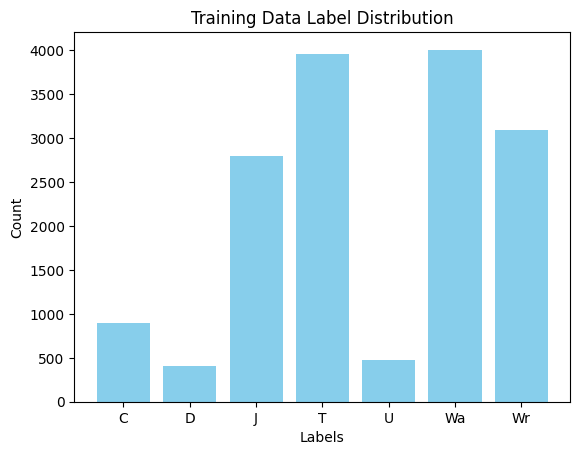


Test Data:
Label Distribution:
Label C: 201 samples
Label D: 112 samples
Label J: 734 samples
Label T: 1010 samples
Label U: 128 samples
Label Wa: 961 samples
Label Wr: 765 samples


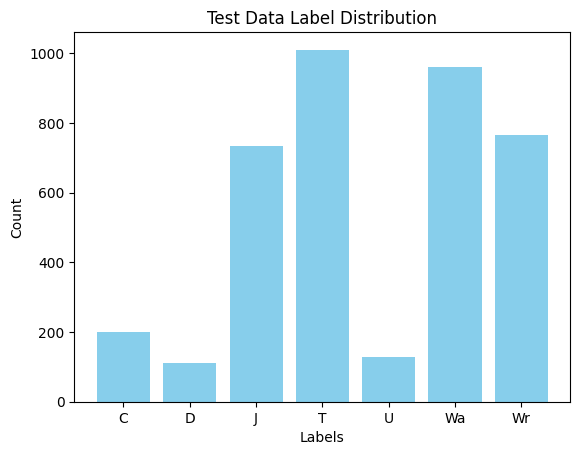

In [10]:
import numpy as np
import collections
import matplotlib.pyplot as plt

def label_distribution(y, title="Label Distribution"):
    """
    Calculate and plot the label distribution for a given dataset.

    Parameters:
    - y: array-like, labels of the dataset.
    - title: str, title for the plot.

    Returns:
    - Dictionary with label distributions.
    """
    # Calculate label distributions
    distribution = collections.Counter(y)

    # Print the distribution
    print("Label Distribution:")
    for label, count in sorted(distribution.items()):
        print(f"Label {label}: {count} samples")

    # Plot the distribution
    labels, counts = zip(*sorted(distribution.items()))
    plt.bar(labels, counts, color='skyblue')
    plt.xlabel("Labels")
    plt.ylabel("Count")
    plt.title(title)
    plt.xticks(labels)
    plt.show()

    # Return distribution as a dictionary
    return dict(distribution)



print("Training Data:")
train_distribution = label_distribution(y_train, title="Training Data Label Distribution")

print("\nTest Data:")
test_distribution = label_distribution(y_test, title="Test Data Label Distribution")
